# Подготовка данных для практических работ

Предметная область всех пяти работ — **онлайн-кинотеатр**: система должна подсказывать зрителю, какие фильмы ему стоит посмотреть.

Источник данных — **MovieLens 32M** (GroupLens, май 2024): 32 млн оценок от 200 948 пользователей по 87 585 фильмам за период с 1995 по октябрь 2023 года. Оценки выставлены по шкале от 0.5 до 5.0 с шагом 0.5, у каждой есть время выставления.

Целиком этот набор не подходит для учебных работ по двум причинам:
1. **Актуальность.** Основная масса оценок и фильмов относится к прошлым десятилетиям, а нам нужен современный каталог.
2. **Размер.** Матрица «пользователь × фильм» размером 200 тыс. × 87 тыс. не помещается в память в плотном виде, а алгоритмы в работах реализуются вручную, чтобы понять их устройство.

Поэтому в этом ноутбуке формируется **свежий срез**: оценки последних лет по фильмам последних лет, несколько тысяч пользователей и фильмов. Срез один раз сохраняется в `data/ml_slice/` и затем используется во всех работах — так результаты разных алгоритмов можно честно сравнить в работе №5.

Весь повторно используемый код (загрузка, формирование среза, разбиение, метрики) вынесен в модуль `ml_common.py`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from zipfile import ZipFile

import ml_common as mc

Единый стиль графиков: один цвет для всех однородных данных, приглушённая сетка

In [2]:
MAIN_COLOR = "#3b6ea8"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Загрузка данных

Архив нужно скачать со страницы https://grouplens.org/datasets/movielens/32m/ (файл `ml-32m.zip`, около 240 МБ) и положить **без распаковки** в папку `data/` рядом с ноутбуком. Модуль читает файлы прямо из архива.

Архив содержит четыре таблицы:
- `ratings.csv` — оценки: `userId, movieId, rating, timestamp`;
- `movies.csv` — фильмы: `movieId, title, genres` (год выпуска записан в названии, жанры — через `|`);
- `links.csv` — связь с внешними базами: `movieId, imdbId, tmdbId`;
- `tags.csv` — теги, которые пользователи ставили фильмам.

In [3]:
assert mc.ZIP_PATH.exists(), f"Положите архив ml-32m.zip в папку {mc.DATA_DIR.resolve()}"

movies = mc.read_movies()
links = mc.read_links()

print(f"Фильмов в каталоге: {len(movies):,}")
print(movies[["movieId", "title", "year", "genre_list"]].head())
print()
print(movies[["movieId", "year"]].info())
print(f"\nФильмов без года в названии: {movies['year'].isna().sum()}")
print(f"Фильмов без жанров: {(movies['genre_list'].str.len() == 0).sum()}")

Фильмов в каталоге: 87,585
   movieId                               title  year  \
0        1                    Toy Story (1995)  1995   
1        2                      Jumanji (1995)  1995   
2        3             Grumpier Old Men (1995)  1995   
3        4            Waiting to Exhale (1995)  1995   
4        5  Father of the Bride Part II (1995)  1995   

                                          genre_list  
0  [Adventure, Animation, Children, Comedy, Fantasy]  
1                     [Adventure, Children, Fantasy]  
2                                  [Comedy, Romance]  
3                           [Comedy, Drama, Romance]  
4                                           [Comedy]  

<class 'pandas.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  87585 non-null  int64
 1   year     86968 non-null  Int64
dtypes: Int64(1), int64(1)
memory usage: 1.4 MB
None

Фильмов бе

Функция `read_movies` сразу разбирает таблицу фильмов:
- год выпуска извлекается регулярным выражением из конца названия — «Inception (2010)» → 2010. Он понадобится для отбора свежих фильмов и как признак контента в работе №5;
- строка жанров `Action|Sci-Fi` превращается в список и в 19 колонок 0/1 (one-hot кодирование). One-hot удобен тем, что каждый фильм становится числовым вектором: с ним работают меры сходства (работы 1 и 5) и метод главных компонент (работа 4).

# Анализ исходных данных

Распределение оценок по годам

Читать все 32 млн строк в память ради подсчёта не нужно: файл читается кусками по 2 млн строк, и для каждого куска накапливаются только счётчики. Параллельно для оценок, выставленных начиная с 2019 года, считается распределение по году выпуска оцениваемого фильма — это покажет, какие фильмы смотрят в последние годы.

In [4]:
movie_year = movies.set_index("movieId")["year"]
by_rating_year = pd.Series(dtype="float64")
by_movie_year_recent = pd.Series(dtype="float64")
users_by_year = {}

with ZipFile(mc.ZIP_PATH) as zf:
    with zf.open(f"{mc.ZIP_FOLDER}/ratings.csv") as f:
        for chunk in pd.read_csv(f, usecols=["userId", "movieId", "timestamp"], chunksize=2_000_000):
            years = pd.to_datetime(chunk["timestamp"], unit="s").dt.year
            by_rating_year = by_rating_year.add(years.value_counts(), fill_value=0)

            # уникальные пользователи по годам
            for year, users in chunk.groupby(years)["userId"]:
                users_by_year.setdefault(year, set()).update(users.unique())

            recent = chunk[years >= 2019]
            by_movie_year_recent = by_movie_year_recent.add(
                recent["movieId"].map(movie_year).value_counts(), fill_value=0)

by_rating_year = by_rating_year.sort_index().astype(int)
users_by_year = pd.Series({y: len(u) for y, u in users_by_year.items()}).sort_index()

print("Оценок и активных пользователей по годам:")
print(pd.DataFrame({"оценок": by_rating_year, "пользователей": users_by_year}).tail(12))

Оценок и активных пользователей по годам:
       оценок  пользователей
2012   695493           8599
2013   563301           7925
2014   518537           7101
2015  1743866          15661
2016  1918739          15705
2017  1827953          14481
2018  1391057          13114
2019  1385467          12345
2020  1688159          14525
2021  1239912          12109
2022   913105           9862
2023   794054           8847


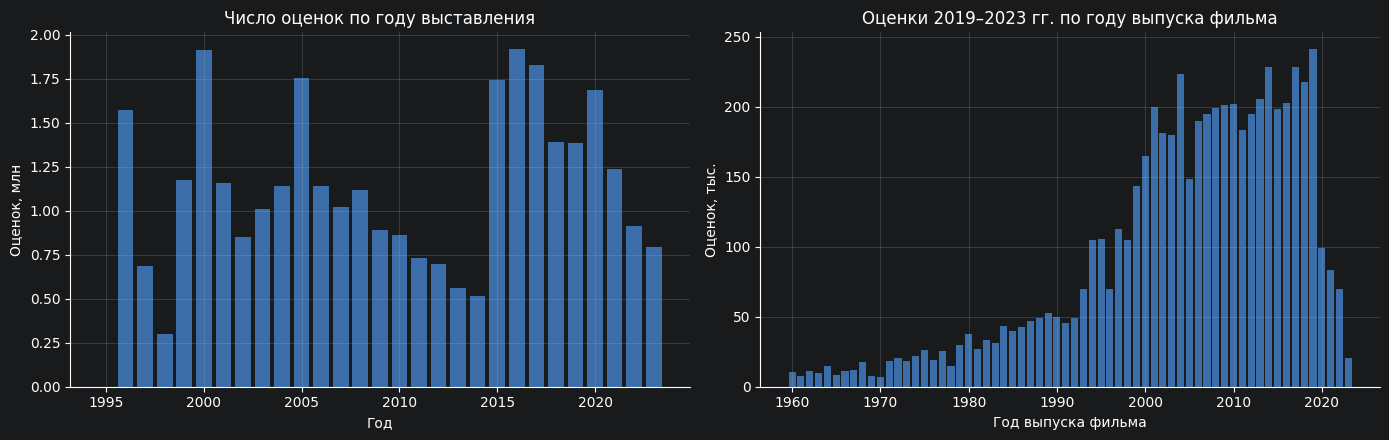

Доля оценок 2019–2023 гг., приходящихся на фильмы 2010 года и новее: 39.7%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(by_rating_year.index, by_rating_year.values / 1e6, color=MAIN_COLOR, width=0.8)
axes[0].set_title("Число оценок по году выставления")
axes[0].set_xlabel("Год")
axes[0].set_ylabel("Оценок, млн")

recent_years = by_movie_year_recent.sort_index()
recent_years = recent_years[recent_years.index >= 1960]
axes[1].bar(recent_years.index.astype(int), recent_years.values / 1e3, color=MAIN_COLOR, width=0.8)
axes[1].set_title("Оценки 2019–2023 гг. по году выпуска фильма")
axes[1].set_xlabel("Год выпуска фильма")
axes[1].set_ylabel("Оценок, тыс.")

plt.tight_layout()
plt.show()

share_fresh = by_movie_year_recent[by_movie_year_recent.index >= 2010].sum() / by_movie_year_recent.sum()
print(f"Доля оценок 2019–2023 гг., приходящихся на фильмы 2010 года и новее: {share_fresh:.1%}")

Левый график показывает, насколько активно пользователи оценивали фильмы в каждом году, правый — какие фильмы оценивают в последние годы. Эти графики — основа для выбора двух временных порогов:
- **период оценок**: берутся последние годы, в которых ещё достаточно активности, чтобы срез получился содержательным;
- **год выпуска фильмов**: каталог онлайн-кинотеатра должен состоять из современных фильмов, но не только из совсем новых — фильмы 2010-х годов по-прежнему активно смотрят.

Выбранные значения задаются ниже в разделе «Формирование среза». Если графики покажут, что в выбранном периоде слишком мало данных, пороги можно сдвинуть.

# Формирование среза

Параметры среза

- `START_DATE` — с какой даты берутся оценки. 2019–2023 годы — это почти пять лет современного поведения пользователей. Более ранние оценки отражают устаревший каталог и привычки;
- `MIN_MOVIE_YEAR` — минимальный год выпуска фильма. Фильмы с 2010 года образуют каталог, близкий к современному онлайн-кинотеатру;
- `N_MOVIES` — сколько самых оцениваемых фильмов взять. У редких фильмов почти нет общих зрителей с другими фильмами, поэтому коллаборативные методы (работы 1 и 3) на них не работают;
- `N_USERS` — сколько пользователей случайно отобрать. Пользователи берутся **случайно**, а не по активности: иначе в срез попали бы только «супер-зрители» с тысячами оценок, и выводы были бы смещены;
- `MIN_USER_RATINGS` — минимум оценок у пользователя. 20 оценок — столько же гарантирует сам MovieLens: этого достаточно, чтобы составить профиль вкуса и ещё оставить часть оценок на проверку;
- `MIN_MOVIE_RATINGS` — минимум оценок у фильма, чтобы для него можно было надёжно считать сходство и средние значения.

Ожидаемый размер — около 2 тыс. пользователей × 3 тыс. фильмов. Плотная матрица такого размера занимает около 50 МБ, поэтому с ней можно работать напрямую: считать сходство всех пар и выполнять SVD без специальных библиотек.

In [6]:
START_DATE = "2019-01-01"
END_DATE = None             # до конца данных (октябрь 2023)
MIN_MOVIE_YEAR = 2010
N_MOVIES = 3000
N_USERS = 2000
MIN_USER_RATINGS = 20
MIN_MOVIE_RATINGS = 10
RANDOM_STATE = 42

Загрузка оценок за выбранный период

Функция `read_ratings` читает файл кусками и сразу отбрасывает оценки вне периода, поэтому в памяти остаётся только нужная часть.

In [7]:
ratings_period = mc.read_ratings(start_date=START_DATE, end_date=END_DATE)

print(f"Оценок за период: {len(ratings_period):,}")
print(f"Пользователей: {ratings_period['userId'].nunique():,}")
print(f"Фильмов: {ratings_period['movieId'].nunique():,}")

Оценок за период: 6,020,697
Пользователей: 36,263
Фильмов: 76,375


Построение среза

Последний шаг `build_slice` — итеративное разрежение (k-core). Удаление редких фильмов уменьшает число оценок у некоторых пользователей, и они перестают проходить порог `MIN_USER_RATINGS`; удаление таких пользователей, в свою очередь, уменьшает число оценок у фильмов. Поэтому фильтры повторяются, пока оба условия не начнут выполняться одновременно. Из-за этого итоговое число пользователей и фильмов получается немного меньше заданного.

In [8]:
ratings, movies_slice = mc.build_slice(
    ratings_period, movies,
    min_movie_year=MIN_MOVIE_YEAR,
    n_movies=N_MOVIES,
    n_users=N_USERS,
    min_user_ratings=MIN_USER_RATINGS,
    min_movie_ratings=MIN_MOVIE_RATINGS,
    random_state=RANDOM_STATE,
)

print()
mc.describe_slice(ratings)

Оценок свежих фильмов (год >= 2010): 2,376,592
После выбора 3000 популярных фильмов: 2,162,432 оценок
Подходящих пользователей: 22,020, выбрано: 2,000
k-core разрежение завершено за 3 итераций

Пользователей: 1,988
Фильмов:       2,191
Оценок:        175,072
Плотность матрицы: 4.02%
Оценок на пользователя: медиана 57
Оценок на фильм:        медиана 30
Период: 2019-01-01 — 2023-10-13


Плотность матрицы — доля заполненных клеток «пользователь × фильм». В реальных системах она обычно составляет доли процента: каждый пользователь видел ничтожную часть каталога. Именно поэтому рекомендательные методы нужны: они должны оценить пустые клетки.

# Анализ среза

Распределение оценок и активности

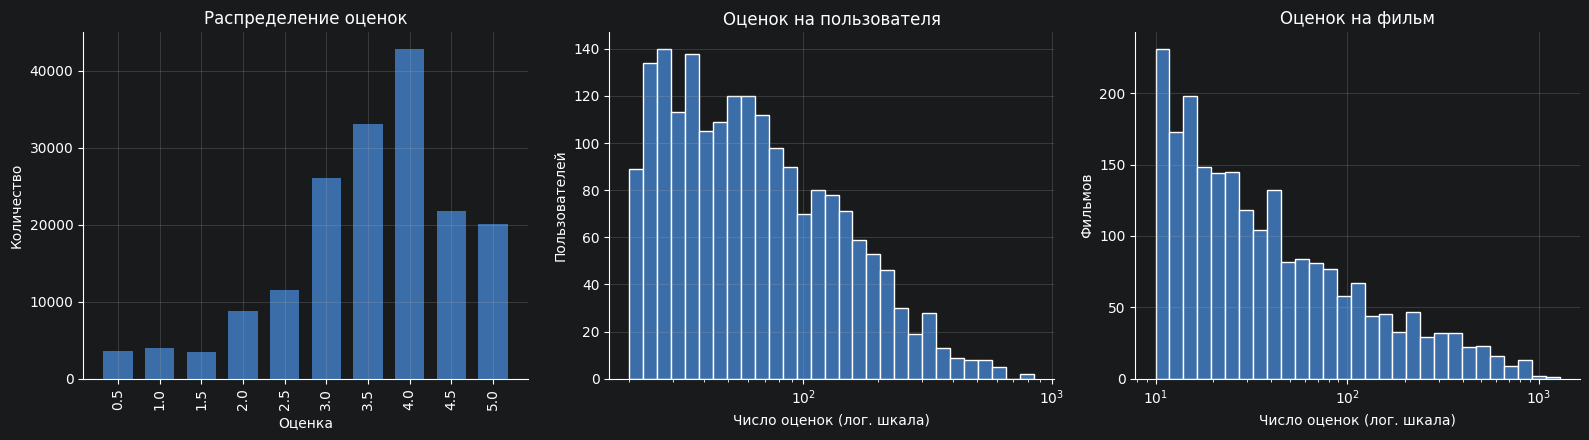

Средняя оценка: 3.546, стандартное отклонение: 1.030
Доля оценок >= 4.0: 48.4%


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

rating_counts = ratings["rating"].value_counts().sort_index()
axes[0].bar(rating_counts.index, rating_counts.values, width=0.35, color=MAIN_COLOR)
axes[0].set_title("Распределение оценок")
axes[0].set_xlabel("Оценка")
axes[0].set_ylabel("Количество")
axes[0].set_xticks(rating_counts.index)
axes[0].tick_params(axis="x", rotation=90)

per_user = ratings.groupby("userId").size()
axes[1].hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 30),
             color=MAIN_COLOR, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Оценок на пользователя")
axes[1].set_xlabel("Число оценок (лог. шкала)")
axes[1].set_ylabel("Пользователей")

per_movie = ratings.groupby("movieId").size()
axes[2].hist(per_movie, bins=np.logspace(np.log10(per_movie.min()), np.log10(per_movie.max()), 30),
             color=MAIN_COLOR, edgecolor="white")
axes[2].set_xscale("log")
axes[2].set_title("Оценок на фильм")
axes[2].set_xlabel("Число оценок (лог. шкала)")
axes[2].set_ylabel("Фильмов")

plt.tight_layout()
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.3f}, стандартное отклонение: {ratings['rating'].std():.3f}")
print(f"Доля оценок >= {mc.RELEVANCE_THRESHOLD}: {(ratings['rating'] >= mc.RELEVANCE_THRESHOLD).mean():.1%}")

Что важно в этих графиках для дальнейших работ:
- **Смещение оценок.** Пользователи чаще ставят высокие оценки, чем низкие, а у каждого есть своя «точка отсчёта»: один ставит 4 хорошему фильму, другой — 5. Поэтому в работе №1 оценки центрируются по среднему пользователя (коэффициент Пирсона делает это автоматически), а в работе №3 в модель SVD добавляются смещения пользователя и фильма.
- **Длинный хвост.** Число оценок на пользователя и на фильм распределено очень неравномерно (поэтому шкала логарифмическая): немногие популярные фильмы собирают большую часть оценок. Это порождает «популярностное смещение» — простые алгоритмы склонны рекомендовать всем одни и те же хиты.
- **Порог релевантности.** Фильм считается понравившимся, если оценка не ниже 4.0. Этот порог используется в метриках топ-N рекомендаций во всех работах.

Распределение жанров

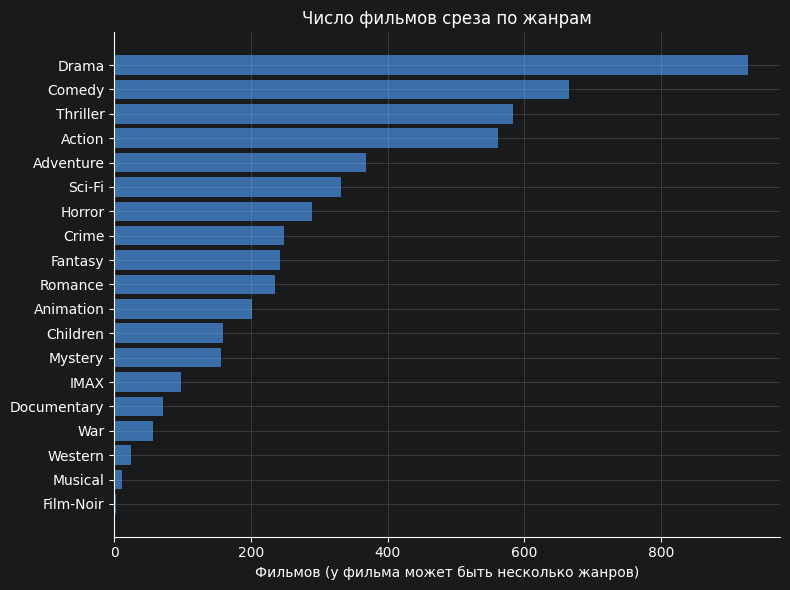

Жанров на фильм в среднем: 2.39


In [10]:
genre_counts = movies_slice[mc.GENRES].sum().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(genre_counts.index, genre_counts.values, color=MAIN_COLOR)
plt.title("Число фильмов среза по жанрам")
plt.xlabel("Фильмов (у фильма может быть несколько жанров)")
plt.tight_layout()
plt.show()

print(f"Жанров на фильм в среднем: {movies_slice['genre_list'].str.len().mean():.2f}")

Жанры — главный признак контента в MovieLens. Они понадобятся в работе №2 (состояния Марковской цепи — жанровые группы), в работе №3 (интерпретация скрытых факторов SVD), в работе №4 (жанровые предпочтения пользователей как признаки для PCA) и в работе №5 (профиль пользователя). Жанр IMAX — это формат показа, а не жанр; в дальнейших работах это стоит учитывать.

Как пользователи выставляют оценки во времени

Для работы №2 важно понимать, что время в MovieLens — это момент **выставления оценки**, а не просмотра. Многие пользователи оценивают фильмы пачками: открывают сайт и подряд оценивают десятки ранее просмотренных фильмов. Проверим, как часто между соседними оценками одного пользователя проходят секунды, а как часто — дни.

Интервал между соседними оценками одного пользователя:
  до 1 минуты : 68.4%
  до 1 часа   : 86.5%
  до 1 суток  : 89.4%
  больше суток : 10.6%

Медиана числа разных дней с оценками у пользователя: 3


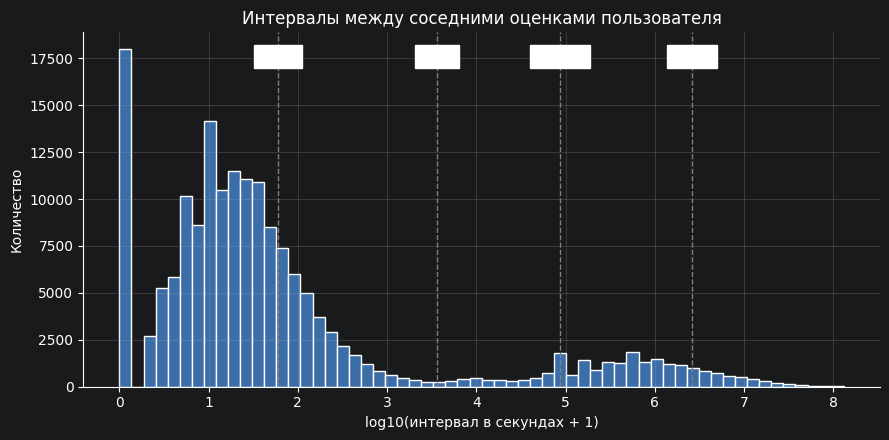

In [11]:
gaps = ratings.sort_values(["userId", "timestamp"]).groupby("userId")["timestamp"].diff().dropna()

print("Интервал между соседними оценками одного пользователя:")
for label, seconds in [("до 1 минуты", 60), ("до 1 часа", 3600), ("до 1 суток", 86400)]:
    print(f"  {label:12}: {(gaps < seconds).mean():.1%}")
print(f"  больше суток : {(gaps >= 86400).mean():.1%}")

days_per_user = ratings.groupby("userId")["datetime"].apply(lambda s: s.dt.date.nunique())
print(f"\nМедиана числа разных дней с оценками у пользователя: {days_per_user.median():.0f}")

plt.figure(figsize=(9, 4.5))
plt.hist(np.log10(gaps + 1), bins=60, color=MAIN_COLOR, edgecolor="white")
for seconds, label in [(60, "1 мин"), (3600, "1 час"), (86400, "1 сутки"), (86400 * 30, "1 мес.")]:
    plt.axvline(np.log10(seconds), color="gray", linestyle="--", linewidth=1)
    plt.text(np.log10(seconds), plt.ylim()[1] * 0.95, label, ha="center", va="top",
             backgroundcolor="white", fontsize=9)
plt.title("Интервалы между соседними оценками пользователя")
plt.xlabel("log10(интервал в секундах + 1)")
plt.ylabel("Количество")
plt.tight_layout()
plt.show()

Если большая часть интервалов короче нескольких минут, то последовательность оценок внутри одного сеанса отражает скорее порядок, в котором сайт показывал фильмы, чем порядок просмотра. В работе №2 это учитывается так: переходы Марковской цепи строятся между жанровыми группами по порядку оценивания, а в выводах эта оговорка указывается явно. Длинные интервалы (дни и месяцы) дают материал для непрерывной цепи, где важно время пребывания в состоянии.

# Временное разбиение на обучающую и тестовую выборки

Для каждого пользователя его оценки сортируются по времени, и **последние 20 %** уходят в тестовую выборку. Случайное разбиение здесь не подходит: модель видела бы «будущие» оценки пользователя и подсматривала бы ответы. Временное разбиение моделирует реальную работу системы — по прошлому пользователя предсказать, что он оценит дальше.

Тестовые оценки играют роль **реакции пользователя на рекомендации** (Примечание 2 к работе №1): если система рекомендовала фильм, а пользователь потом оценил его на 4–5, рекомендация удачная.

Разбиение выполняется один раз и сохраняется, поэтому все работы проверяются на одних и тех же данных.

In [12]:
train, test = mc.temporal_split(ratings, test_ratio=0.2)

print(f"Обучающая выборка: {len(train):,} оценок")
print(f"Тестовая выборка:  {len(test):,} оценок ({len(test) / len(ratings):.1%})")
print(f"Пользователей в тесте: {test['userId'].nunique():,}")

cold_movies = set(test["movieId"]) - set(train["movieId"])
cold_share = test["movieId"].isin(cold_movies).mean()
print(f"\nФильмов, которые встречаются только в тесте: {len(cold_movies)}")
print(f"Доля тестовых оценок по таким фильмам: {cold_share:.1%}")

relevant_per_user = test[test["rating"] >= mc.RELEVANCE_THRESHOLD].groupby("userId").size()
print(f"\nПользователей с хотя бы одним понравившимся фильмом в тесте: {len(relevant_per_user):,}")
print(f"Понравившихся тестовых фильмов на пользователя: медиана {relevant_per_user.median():.0f}")

Обучающая выборка: 140,054 оценок
Тестовая выборка:  35,018 оценок (20.0%)
Пользователей в тесте: 1,988

Фильмов, которые встречаются только в тесте: 1
Доля тестовых оценок по таким фильмам: 0.1%

Пользователей с хотя бы одним понравившимся фильмом в тесте: 1,920
Понравившихся тестовых фильмов на пользователя: медиана 6


Фильмы, которые встречаются только в тестовой выборке, — это проблема **«холодного старта» объекта**: у коллаборативных методов (работы 1–3) по ним нет ни одной оценки, и предсказать их они не могут. Методы на основе контента (работа №5) с этим справляются, потому что жанры и год выпуска известны сразу. Это одно из сравнений, которое будет сделано в работе №5.

# Теги и связь с TMDB

Для работы №5 понадобятся дополнительные признаки контента:
- **теги** — свободные метки пользователей («atmospheric», «twist ending», «visually appealing»). Они описывают фильм точнее, чем жанры. Теги берутся за всё время по фильмам среза, так как это характеристики фильма, а не поведения конкретного пользователя;
- **tmdbId** — идентификатор фильма в The Movie Database. По нему можно подтянуть язык оригинала, популярность и рейтинг TMDB.

In [13]:
slice_movie_ids = set(movies_slice["movieId"])

tags = mc.read_tags()
tags_slice = tags[tags["movieId"].isin(slice_movie_ids)].reset_index(drop=True)
links_slice = links[links["movieId"].isin(slice_movie_ids)].reset_index(drop=True)

print(f"Тегов по фильмам среза: {len(tags_slice):,}")
print(f"Фильмов среза с хотя бы одним тегом: {tags_slice['movieId'].nunique():,} из {len(slice_movie_ids):,}")
print("\nСамые частые теги:")
print(tags_slice["tag"].value_counts().head(15))

print(f"\nФильмов с tmdbId: {links_slice['tmdbId'].notna().sum():,} из {len(links_slice):,}")

Тегов по фильмам среза: 514,131
Фильмов среза с хотя бы одним тегом: 2,187 из 2,191

Самые частые теги:
tag
sci-fi                4140
visually appealing    4129
action                3800
funny                 3259
cinematography        3174
atmospheric           2244
comedy                2211
superhero             2186
thought-provoking     2173
thriller              2158
predictable           2156
social commentary     1762
time travel           1755
dystopia              1729
surreal               1680
Name: count, dtype: int64

Фильмов с tmdbId: 2,191 из 2,191


# Сохранение среза

Срез сохраняется в `data/ml_slice/` в виде CSV-файлов. В следующих работах его достаточно загрузить одной строкой:

```python
import ml_common as mc
data = mc.load_slice()
train, test, movies = data["train"], data["test"], data["movies"]
```

In [14]:
mc.save_slice(
    train=train,
    test=test,
    movies=movies_slice,
    links=links_slice,
    tags=tags_slice,
)

Сохранено: data\ml_slice\train.csv (140,054 строк)
Сохранено: data\ml_slice\test.csv (35,018 строк)
Сохранено: data\ml_slice\movies.csv (2,191 строк)
Сохранено: data\ml_slice\links.csv (2,191 строк)
Сохранено: data\ml_slice\tags.csv (514,131 строк)


Проверка: загруженный срез совпадает с сохранённым

In [15]:
data = mc.load_slice()
assert len(data["train"]) == len(train) and len(data["test"]) == len(test)
assert data["movies"]["genre_list"].iloc[0] == movies_slice["genre_list"].iloc[0]
print("Срез загружается корректно:", ", ".join(f"{k} ({len(v):,})" for k, v in data.items()))

Срез загружается корректно: links (2,191), movies (2,191), tags (514,131), test (35,018), train (140,054)


# Итоги

Подготовлен единый набор данных для всех практических работ:
- предметная область — онлайн-кинотеатр с каталогом фильмов 2010-х и 2020-х годов;
- оценки пользователей за 2019–2023 годы из MovieLens 32M;
- срез из нескольких тысяч пользователей и фильмов, на котором алгоритмы можно реализовать вручную.

Схема проверки, общая для всех работ:
- **разбиение** — последние 20 % оценок каждого пользователя по времени уходят в тест;
- **прогноз оценки** — MAE и RMSE (`mc.mae`, `mc.rmse`);
- **топ-N рекомендации** — Precision@K, Recall@K, NDCG@K (`mc.ranking_metrics`), фильм релевантен при оценке не ниже 4.0;
- **особенности данных**, которые нужно учитывать: смещение оценок у разных пользователей, популярностное смещение, пакетное выставление оценок, «холодный старт» части фильмов.